# phase 2 :
    1- loading , spliting , training the models then evaluating 

In [1]:
from prepration import load_data , check_data , split_data

df= load_data()
check_data(df)

Shape: (10299, 565)
Duplicate rows: 0
Missing values: 0


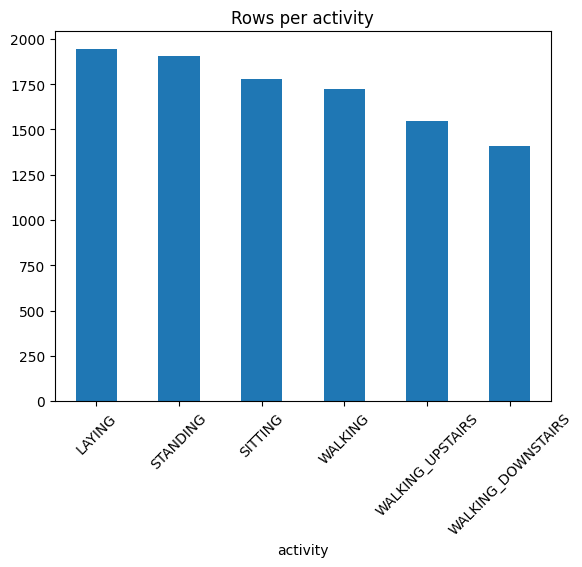

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

df["activity"].value_counts().plot(kind="bar", title="Rows per activity")
plt.xticks(rotation=45)
plt.show()

In [6]:
X_train , y_train ,groups_train, X_test , y_test = split_data(df)

print("train :" , X_train.shape , "test :" , X_test.shape)
print("Overlap:", set(groups_train) & set(df.loc[X_test.index, "subject_id"]))

train : (7352, 561) test : (2947, 561)
Overlap: set()


In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


ridge = make_pipeline(StandardScaler() , LogisticRegression(max_iter=5000))
lasso = make_pipeline(StandardScaler() , LogisticRegression(l1_ratio=1 , solver = "saga" , tol = 0.01 , random_state=35))

models = {"ridge" : ridge , "lasso" : lasso}

for name , model in models.items() : 
    model.fit(X_train , y_train)
    print(name , "zero weights :" , (model[-1].coef_ == 0).sum() , "of" , model[-1].coef_.size)


ridge zero weights : 0 of 3366
lasso zero weights : 51 of 3366
